# 📊 Loan Default Risk Analysis: Identifying Credit Risk & Defaulted Loan Exposure

### Data Analysis & Credit Risk Segmentation

This notebook analyses historical loan data to investigate patterns associated with loan defaults and identify segments with higher observed default rates or substantial defaulted-loan exposure.

The analysis uses Python, Pandas, NumPy, and Matplotlib to perform data understanding, data-quality checks, feature engineering, exploratory data analysis, and multi-factor credit-risk segmentation.

The results will be compared with the SQL analysis and Power BI dashboard developed for this project.

In [2]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")


Libraries imported successfully!


In [38]:

# Load the loan dataset

df = pd.read_csv("../Data/loan_train.csv")

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")


Dataset loaded successfully!
Number of rows: 27003
Number of columns: 47



## 3. Initial Data Inspection

This section examines the structure, column names, data types, and summary statistics of the loan dataset. These checks help us understand the available variables and identify potential data-quality issues before performing exploratory data analysis.


In [4]:
# Display the first five records
display(df.head())

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,last_credit_pull_d,pub_rec_bankruptcies
0,540179,697401,10000,10000,9975.0,36 months,13.23%,338.05,C,C1,Progressive Business Publications,4 years,RENT,37000.0,Not Verified,Jul-10,0,https://lendingclub.com/browse/loanDetail.acti...,Borrower added on 07/01/10 > I will be using...,debt_consolidation,Debt,194xx,PA,16.86,0,Sep-02,0,37.0,NaN,9,0,10217,62.70%,14,0.0,0.0,11973.610590,11943.68,10000.00,1973.61,0.0,0.00,0.0,Sep-12,3536.63,Mar-14,0.0
1,585434,752191,14000,14000,13775.0,36 months,7.88%,437.94,A,A5,2wire,< 1 year,RENT,105000.0,Not Verified,Sep-10,0,https://lendingclub.com/browse/loanDetail.acti...,Borrower added on 09/26/10 > I need this loa...,credit_card,Credit Card Debt Consolidation,945xx,CA,6.33,0,Jul-05,0,NaN,NaN,9,0,13307,28.80%,18,0.0,0.0,15723.484220,15470.79,14000.00,1723.48,0.0,0.00,0.0,May-13,2603.31,Jan-16,0.0
2,457736,569298,9475,9475,9475.0,36 months,8.94%,301.04,A,A5,City of Zeigler,9 years,OWN,27000.0,Not Verified,Nov-09,0,https://lendingclub.com/browse/loanDetail.acti...,569298 added on 11/06/09 > I am a police off...,debt_consolidation,money,628xx,IL,7.07,0,May-99,0,NaN,NaN,5,0,7866,44.70%,17,0.0,0.0,10472.086990,10472.09,9475.00,997.09,0.0,0.00,0.0,May-11,5365.49,Aug-15,0.0
3,734349,930860,4000,4000,4000.0,36 months,7.29%,124.04,A,A4,KENANSVILLE EQUIPMENT CO,10+ years,OWN,35000.0,Not Verified,Apr-11,0,https://lendingclub.com/browse/loanDetail.acti...,NaN,credit_card,PRSNL LN,283xx,NC,28.80,0,Dec-97,0,NaN,NaN,13,0,29358,69.10%,18,0.0,0.0,4425.256588,4425.26,4000.00,425.26,0.0,0.00,0.0,Jul-13,1336.22,May-15,0.0
4,1050080,1281522,3600,3600,3600.0,36 months,6.62%,110.54,A,A2,Hill and Knowlton,1 year,RENT,60000.0,Not Verified,Dec-11,1,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Organizing finances,223xx,VA,21.54,0,Apr-99,1,NaN,NaN,12,0,15502,70.10%,32,0.0,0.0,2321.340000,2321.34,2004.17,306.88,0.0,10.29,0.0,Sep-13,110.54,May-16,0.0


In [5]:
# Inspect dataset dimensions
print("Dataset shape:", df.shape)

# Review column names
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (27003, 47)

Column names:
['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'pub_rec_bankruptcies']


In [6]:

# Review data types and non-null counts
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27003 entries, 0 to 27002
Data columns (total 47 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       27003 non-null  int64  
 1   member_id                27003 non-null  int64  
 2   loan_amnt                27003 non-null  int64  
 3   funded_amnt              27003 non-null  int64  
 4   funded_amnt_inv          27003 non-null  float64
 5   term                     27003 non-null  object 
 6   int_rate                 27003 non-null  object 
 7   installment              27003 non-null  float64
 8   grade                    27003 non-null  object 
 9   sub_grade                27003 non-null  object 
 10  emp_title                25321 non-null  object 
 11  emp_length               26273 non-null  object 
 12  home_ownership           27003 non-null  object 
 13  annual_inc               27003 non-null  float64
 14  verification_status   

In [7]:

# Generate descriptive statistics for numeric columns
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
id,27003.0,676300.725660,209044.025722,54734.00,512663.000000,657052.0000,8.271015e+05,1.077430e+06
member_id,27003.0,842247.267341,264254.127295,70699.00,661775.500000,840072.0000,1.035238e+06,1.314167e+06
loan_amnt,27003.0,11087.946710,7392.758683,500.00,5300.000000,9750.0000,1.500000e+04,3.500000e+04
funded_amnt,27003.0,10816.216717,7131.666342,500.00,5175.000000,9600.0000,1.500000e+04,3.500000e+04
funded_amnt_inv,27003.0,10251.064645,7066.203699,0.00,5000.000000,8731.0261,1.402500e+04,3.500000e+04
installment,27003.0,323.375002,209.866524,15.69,165.805000,277.5700,4.270000e+02,1.302690e+03
annual_inc,27003.0,68777.705736,67648.525419,4000.00,40000.000000,59000.0000,8.200000e+04,6.000000e+06
loan_status,27003.0,0.147280,0.354391,0.00,0.000000,0.0000,0.000000e+00,1.000000e+00
dti,27003.0,13.259037,6.662728,0.00,8.130000,13.3500,1.852000e+01,2.999000e+01
delinq_2yrs,27003.0,0.149169,0.499802,0.00,0.000000,0.0000,0.000000e+00,1.100000e+01



## 4. Data Quality Assessment

This section evaluates the quality and reliability of the loan dataset by examining missing values, duplicate records, data types, and the distribution of loan outcomes. These checks help identify potential issues that could affect the accuracy of the subsequent analysis.

In [8]:

# Count missing values in each column
missing_values = df.isnull().sum()

missing_summary = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
    .to_frame(name="Missing Values")
)

missing_summary["Missing Percentage"] = (
    missing_summary["Missing Values"] / len(df) * 100
).round(2)

display(missing_summary)


,Missing Values,Missing Percentage
mths_since_last_record,25065,92.82
mths_since_last_delinq,17395,64.42
desc,8779,32.51
emp_title,1682,6.23
emp_length,730,2.70
pub_rec_bankruptcies,503,1.86
last_pymnt_d,51,0.19
revol_util,35,0.13
title,9,0.03
last_credit_pull_d,1,0.00


In [9]:

# Check for fully duplicated rows
duplicate_rows = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)


Number of duplicate rows: 0


In [10]:

# Examine the target variable distribution
loan_status_counts = df["loan_status"].value_counts().sort_index()

loan_status_summary = pd.DataFrame({
    "Loan Status": loan_status_counts.index,
    "Loan Count": loan_status_counts.values,
    "Percentage": (
        loan_status_counts.values / len(df) * 100
    ).round(2)
})

display(loan_status_summary)


,Loan Status,Loan Count,Percentage
0,0,23026,85.27
1,1,3977,14.73


In [11]:

# Check the distinct values in loan_status
print("Unique loan_status values:", sorted(df["loan_status"].dropna().unique()))


Unique loan_status values: [np.int64(0), np.int64(1)]



## 5. Feature Engineering and Key Metrics

This section derives key credit-risk metrics and categorical features to support exploratory analysis. The loan status variable is used to distinguish defaulted loans from non-defaulted loans, while additional features help summarize default patterns across loan amount, debt-to-income ratio, and interest-rate segments.


In [12]:

# Calculate overall loan portfolio metrics
total_loans = len(df)
defaulted_loans = (df["loan_status"] == 1).sum()
non_defaulted_loans = (df["loan_status"] == 0).sum()
default_rate = (defaulted_loans / total_loans) * 100

print(f"Total loans: {total_loans:,}")
print(f"Defaulted loans: {defaulted_loans:,}")
print(f"Non-defaulted loans: {non_defaulted_loans:,}")
print(f"Observed default rate: {default_rate:.2f}%")


Total loans: 27,003
Defaulted loans: 3,977
Non-defaulted loans: 23,026
Observed default rate: 14.73%


In [15]:

# Inspect the original interest-rate column
display(df[["int_rate"]].head(10))
print("Data type:", df["int_rate"].dtype)


,int_rate
0,13.23%
1,7.88%
2,8.94%
3,7.29%
4,6.62%
5,8.49%
6,16.07%
7,16.77%
8,10.74%
9,8.49%


Data type: object


In [16]:

# Convert interest rate to numeric percentage points
df["interest_rate"] = (
    df["int_rate"]
    .astype("string")
    .str.replace("%", "", regex=False)
    .str.strip()
)

df["interest_rate"] = pd.to_numeric(
    df["interest_rate"], errors="coerce"
)

display(df[["int_rate", "interest_rate"]].head(10))


,int_rate,interest_rate
0,13.23%,13.23
1,7.88%,7.88
2,8.94%,8.94
3,7.29%,7.29
4,6.62%,6.62
5,8.49%,8.49
6,16.07%,16.07
7,16.77%,16.77
8,10.74%,10.74
9,8.49%,8.49


In [17]:

# Create loan amount bands
df["loan_amount_band"] = pd.cut(
    df["loan_amnt"],
    bins=[-float("inf"), 5000, 10000, 20000, float("inf")],
    labels=["Low", "Medium", "High", "Very High"],
    right=False
)

# Create DTI bands
df["dti_band"] = pd.cut(
    df["dti"],
    bins=[-float("inf"), 10, 20, 30, float("inf")],
    labels=["Low", "Moderate", "High", "Very High"],
    right=False
)

# Create interest-rate bands
df["interest_rate_band"] = pd.cut(
    df["interest_rate"],
    bins=[-float("inf"), 8, 12, 16, float("inf")],
    labels=["Low", "Moderate", "High", "Very High"],
    right=False
)

print("Risk bands created successfully.")


Risk bands created successfully.


In [18]:

display(
    df[
        [
            "loan_amnt", "loan_amount_band",
            "dti", "dti_band",
            "interest_rate", "interest_rate_band",
            "loan_status"
        ]
    ].head(10)
)


,loan_amnt,loan_amount_band,dti,dti_band,interest_rate,interest_rate_band,loan_status
0,10000,High,16.86,Moderate,13.23,High,0
1,14000,High,6.33,Low,7.88,Low,0
2,9475,Medium,7.07,Low,8.94,Moderate,0
3,4000,Low,28.80,High,7.29,Low,0
4,3600,Low,21.54,High,6.62,Low,1
5,7200,Medium,6.96,Low,8.49,Moderate,0
6,15000,High,12.08,Moderate,16.07,Very High,0
7,18000,High,18.42,Moderate,16.77,Very High,1
8,8000,Medium,17.56,Moderate,10.74,Moderate,0
9,3500,Low,7.27,Low,8.49,Moderate,1



## 6. Exploratory Data Analysis (EDA)

This section explores loan default patterns across credit grades, debt-to-income ratios, interest-rate bands, loan amount bands, and loan purposes. The objective is to identify segments with higher observed default rates and understand how defaulted-loan exposure varies across the portfolio.



### 6.1 Default Rate by Credit Grade

This analysis examines observed loan default rates across credit grades A to G to identify differences in credit risk within the loan portfolio. By comparing the number of loans, defaulted loans, and default rates for each grade, the analysis highlights segments with relatively higher and lower observed default rates.


In [20]:

# Calculate loan counts and observed default rates by grade
grade_analysis = (
    df.groupby("grade", observed=True)
    .agg(
        total_loans=("loan_status", "size"),
        defaulted_loans=("loan_status", "sum")
    )
    .reset_index()
)

grade_analysis["default_rate_pct"] = (
    grade_analysis["defaulted_loans"]
    / grade_analysis["total_loans"] * 100
).round(2)

display(grade_analysis.sort_values("grade"))


,grade,total_loans,defaulted_loans,default_rate_pct
0,A,7054,431,6.11
1,B,8189,995,12.15
2,C,5453,956,17.53
3,D,3532,789,22.34
4,E,1858,511,27.50
5,F,698,220,31.52
6,G,219,75,34.25


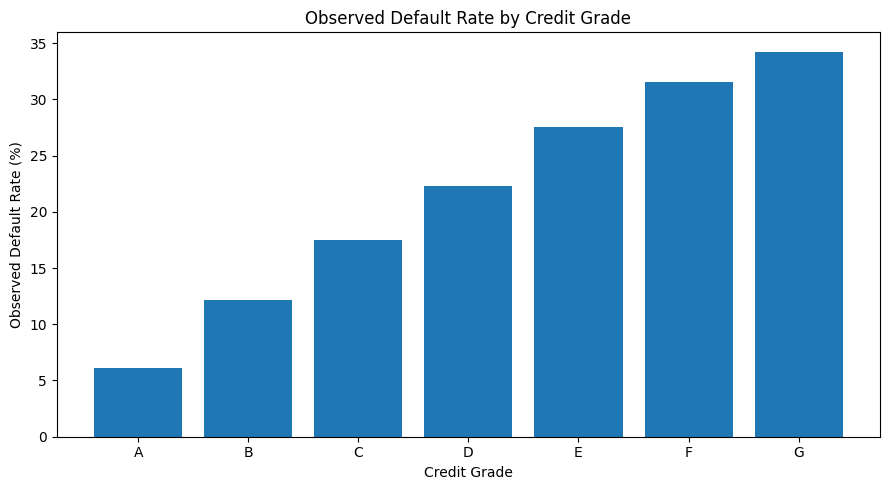

In [21]:

# Visualize observed default rate by credit grade
plt.figure(figsize=(9, 5))

plt.bar(
    grade_analysis["grade"].astype(str),
    grade_analysis["default_rate_pct"]
)

plt.title("Observed Default Rate by Credit Grade")
plt.xlabel("Credit Grade")
plt.ylabel("Observed Default Rate (%)")
plt.tight_layout()
plt.show()



**Key Insight:** The observed default rate increases across credit grades, from approximately 6.11% for Grade A to 34.25% for Grade G. Grades E, F, and G show substantially higher observed default rates than the lower-risk grades.

**Business Implication:** Credit grade can help distinguish segments with different observed default rates. Lenders could consider additional review of higher-risk grades alongside other borrower characteristics. These results show an association, not proof that credit grade itself causes default.



### 6.2 Default Rate by Debt-to-Income (DTI) Band

This analysis compares observed default rates across debt-to-income bands to examine whether borrowers with higher debt burdens relative to their income exhibit different default patterns.


In [22]:

# Calculate default rates by DTI band
dti_analysis = (
    df.groupby("dti_band", observed=True)
    .agg(
        total_loans=("loan_status", "size"),
        defaulted_loans=("loan_status", "sum")
    )
    .reset_index()
)

dti_analysis["default_rate_pct"] = (
    dti_analysis["defaulted_loans"]
    / dti_analysis["total_loans"] * 100
).round(2)

display(dti_analysis)


,dti_band,total_loans,defaulted_loans,default_rate_pct
0,Low,9074,1165,12.84
1,Moderate,12903,1944,15.07
2,High,5026,868,17.27


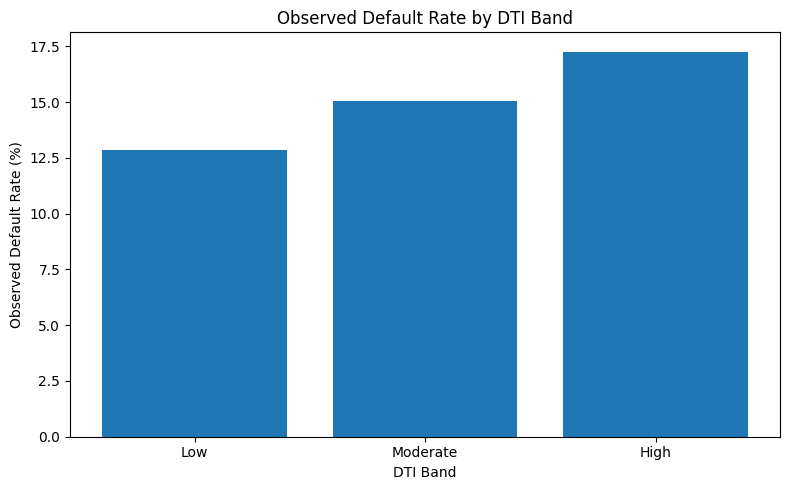

In [23]:

# Visualize observed default rate by DTI band
plt.figure(figsize=(8, 5))

plt.bar(
    dti_analysis["dti_band"].astype(str),
    dti_analysis["default_rate_pct"]
)

plt.title("Observed Default Rate by DTI Band")
plt.xlabel("DTI Band")
plt.ylabel("Observed Default Rate (%)")
plt.tight_layout()
plt.show()



**Key Insight:** The observed default rate increases as the DTI band rises. The Low DTI group has an observed default rate of approximately 12.82%, compared with 15.04% for Moderate DTI and 17.24% for High DTI. This suggests that borrowers with higher debt-to-income ratios may represent higher credit risk in this dataset.

**Business Implication:** DTI can be considered alongside credit grade, interest rate, and other borrower characteristics when assessing credit risk. These are observed associations and do not establish that higher DTI directly causes loan defaults.



### 6.3 Default Rate by Interest Rate Band

This analysis compares observed loan default rates across interest-rate bands to examine how default outcomes vary among loans with different interest rates.


In [24]:

# Calculate default rates by interest-rate band
interest_analysis = (
    df.groupby("interest_rate_band", observed=True)
    .agg(
        total_loans=("loan_status", "size"),
        defaulted_loans=("loan_status", "sum")
    )
    .reset_index()
)

interest_analysis["default_rate_pct"] = (
    interest_analysis["defaulted_loans"]
    / interest_analysis["total_loans"] * 100
).round(2)

display(interest_analysis)


,interest_rate_band,total_loans,defaulted_loans,default_rate_pct
0,Low,5627,307,5.46
1,Moderate,8887,1023,11.51
2,High,8649,1531,17.70
3,Very High,3840,1116,29.06


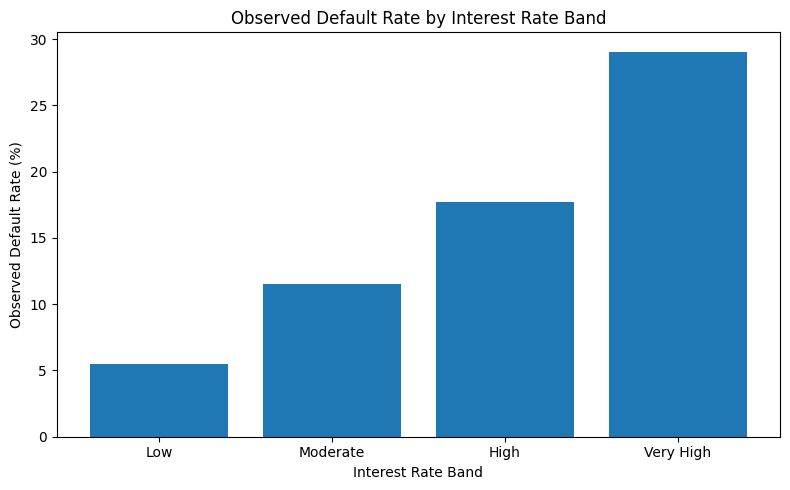

In [25]:

# Visualize observed default rate by interest-rate band
plt.figure(figsize=(8, 5))

plt.bar(
    interest_analysis["interest_rate_band"].astype(str),
    interest_analysis["default_rate_pct"]
)

plt.title("Observed Default Rate by Interest Rate Band")
plt.xlabel("Interest Rate Band")
plt.ylabel("Observed Default Rate (%)")
plt.tight_layout()
plt.show()



**Key Insight:** The observed default rate increases across interest-rate bands. The Low band has the lowest default rate at approximately 5.5%, followed by Moderate at 11.5%, High at 17.7%, and Very High at 29.0%.

**Business Implication:** Interest rates may help distinguish loan segments with different observed default rates. Higher interest rates could reflect higher assessed borrower risk, so this relationship should not be interpreted as proof that higher interest rates cause defaults.



### 6.4 Default Rate by Loan Amount Band

This analysis compares observed loan default rates across loan amount bands to examine whether default outcomes vary with the size of the loan principal.


In [26]:

# Calculate default rates by loan amount band
loan_amount_analysis = (
    df.groupby("loan_amount_band", observed=True)
    .agg(
        total_loans=("loan_status", "size"),
        defaulted_loans=("loan_status", "sum")
    )
    .reset_index()
)

loan_amount_analysis["default_rate_pct"] = (
    loan_amount_analysis["defaulted_loans"]
    / loan_amount_analysis["total_loans"] * 100
).round(2)

display(loan_amount_analysis)


,loan_amount_band,total_loans,defaulted_loans,default_rate_pct
0,Low,5192,731,14.08
1,Medium,8395,1091,13.00
2,High,9291,1356,14.59
3,Very High,4125,799,19.37


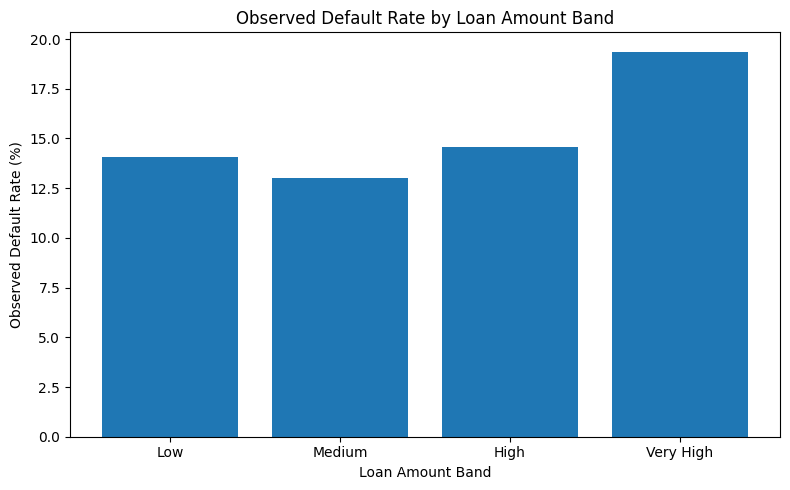

In [27]:

# Visualize observed default rate by loan amount band
plt.figure(figsize=(8, 5))

plt.bar(
    loan_amount_analysis["loan_amount_band"].astype(str),
    loan_amount_analysis["default_rate_pct"]
)

plt.title("Observed Default Rate by Loan Amount Band")
plt.xlabel("Loan Amount Band")
plt.ylabel("Observed Default Rate (%)")
plt.tight_layout()
plt.show()



**Key Insight:** The Very High loan amount band has the highest observed default rate at approximately 19.37%. The Low and High bands show rates of around 14.08% and 14.59%, respectively, while the Medium band has the lowest rate at approximately 13.00%.

**Business Implication:** Larger loan amounts may represent greater principal exposure when a default occurs. Lenders should evaluate loan size alongside borrower credit grade, DTI, and interest rate rather than using loan amount alone to assess default risk.



### 6.5 Default Rate by Loan Purpose

This analysis compares observed loan default rates across different loan purposes to identify categories with relatively higher default rates. The results can help highlight segments for further investigation, while considering differences in sample size across purposes.


In [28]:

# Calculate loan counts and default rates by purpose
purpose_analysis = (
    df.groupby("purpose", dropna=False)
    .agg(
        total_loans=("loan_status", "size"),
        defaulted_loans=("loan_status", "sum")
    )
    .reset_index()
)

purpose_analysis["default_rate_pct"] = (
    purpose_analysis["defaulted_loans"]
    / purpose_analysis["total_loans"] * 100
).round(2)

display(
    purpose_analysis.sort_values(
        "default_rate_pct", ascending=False
    )
)


,purpose,total_loans,defaulted_loans,default_rate_pct
11,small_business,1221,330,27.03
10,renewable_energy,73,13,17.81
7,medical,496,83,16.73
5,house,266,44,16.54
9,other,2704,447,16.53
2,debt_consolidation,12589,1937,15.39
3,educational,215,33,15.35
8,moving,395,59,14.94
12,vacation,256,35,13.67
4,home_improvement,2055,270,13.14


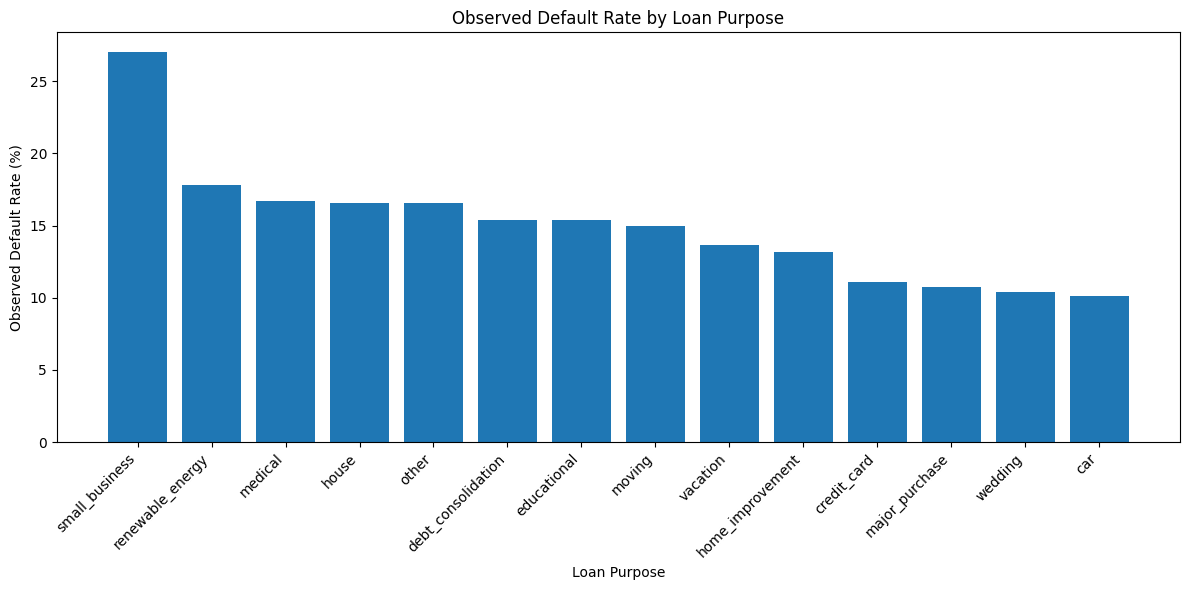

In [29]:

# Visualize observed default rate by loan purpose
purpose_chart = purpose_analysis.sort_values(
    "default_rate_pct", ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    purpose_chart["purpose"].fillna("Unknown").astype(str),
    purpose_chart["default_rate_pct"]
)

plt.title("Observed Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Observed Default Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



**Key Insight:** Small-business loans show the highest observed default rate at approximately 27%, followed by renewable-energy loans at around 18%. Several other purposes, including medical, house, and other, also show relatively high default rates. Car, wedding, and major-purchase loans have comparatively lower observed default rates.

**Business Implication:** Loan purpose may help identify segments for further credit-risk investigation. However, these results should be interpreted alongside the number of loans in each category, since small sample sizes can produce unstable default rates. Loan purpose alone should not determine lending decisions.



### 6.6 Defaulted Loan Amount by Credit Grade

This analysis measures the total original loan principal associated with defaulted loans across credit grades. It complements default-rate analysis by highlighting where defaulted principal exposure is concentrated in the portfolio.


In [30]:

# Calculate defaulted principal exposure by credit grade
defaulted_amount_analysis = (
    df[df["loan_status"] == 1]
    .groupby("grade", observed=True)
    .agg(
        defaulted_loans=("loan_status", "size"),
        defaulted_loan_amount=("loan_amnt", "sum")
    )
    .reset_index()
)

display(defaulted_amount_analysis.sort_values("grade"))


,grade,defaulted_loans,defaulted_loan_amount
0,A,431,3347275
1,B,995,10871725
2,C,956,10679625
3,D,789,9723075
4,E,511,8264825
5,F,220,4176075
6,G,75,1427375


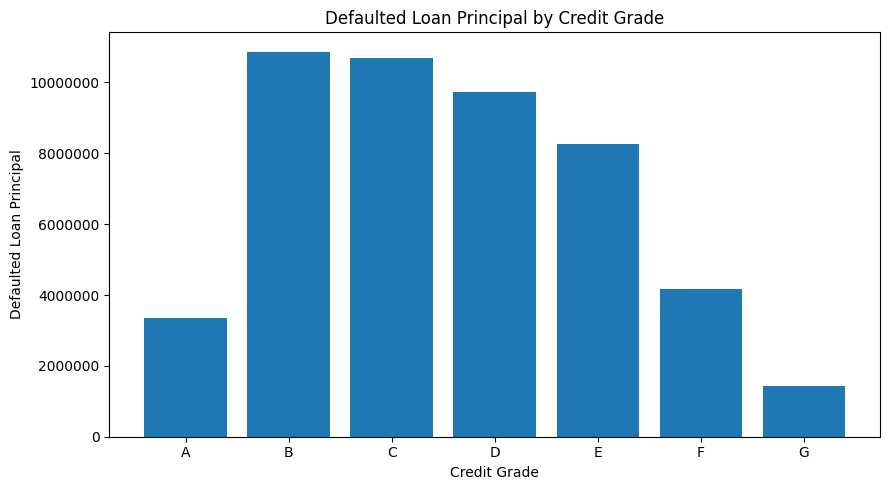

In [31]:

# Visualize defaulted principal exposure by grade
plt.figure(figsize=(9, 5))

plt.bar(
    defaulted_amount_analysis["grade"].astype(str),
    defaulted_amount_analysis["defaulted_loan_amount"]
)

plt.title("Defaulted Loan Principal by Credit Grade")
plt.xlabel("Credit Grade")
plt.ylabel("Defaulted Loan Principal")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()



**Key Insight:** Grades B and C account for the largest amounts of defaulted loan principal, followed by Grades D and E. Although lower credit grades show higher observed default rates, the amount of defaulted principal also depends on the number and size of loans in each grade.

**Business Implication:** Credit-risk monitoring should consider both default rates and defaulted principal exposure. Higher-risk grades may warrant closer review, while grades with larger defaulted principal amounts may require attention because of their contribution to overall portfolio exposure.

**Note:** Defaulted loan principal represents the original amount borrowed on defaulted loans; it is not a measure of actual financial loss or the outstanding balance at default.



### 6.7 Default Rate by Credit Grade and DTI Band

This analysis combines credit grade and debt-to-income (DTI) bands to examine how observed default rates vary across borrower segments. A multi-factor view can reveal differences that may not be visible when each variable is analyzed independently.


In [32]:

# Analyze default rates by credit grade and DTI band
grade_dti_analysis = (
    df.groupby(["grade", "dti_band"], observed=True)
    .agg(
        total_loans=("loan_status", "size"),
        defaulted_loans=("loan_status", "sum"),
        defaulted_loan_amount=(
            "loan_amnt",
            lambda x: x[df.loc[x.index, "loan_status"] == 1].sum()
        )
    )
    .reset_index()
)

grade_dti_analysis["default_rate_pct"] = (
    grade_dti_analysis["defaulted_loans"]
    / grade_dti_analysis["total_loans"] * 100
).round(2)

display(
    grade_dti_analysis.sort_values(
        ["grade", "dti_band"]
    )
)


,grade,dti_band,total_loans,defaulted_loans,defaulted_loan_amount,default_rate_pct
0,A,Low,2975,152,1247775,5.11
1,A,Moderate,2968,181,1417975,6.10
2,A,High,1111,98,681525,8.82
3,B,Low,2670,301,3566775,11.27
4,B,Moderate,4012,488,5218625,12.16
5,B,High,1507,206,2086325,13.67
6,C,Low,1637,280,2936050,17.10
7,C,Moderate,2694,450,5088250,16.70
8,C,High,1122,226,2655325,20.14
9,D,Low,1027,229,2506850,22.30


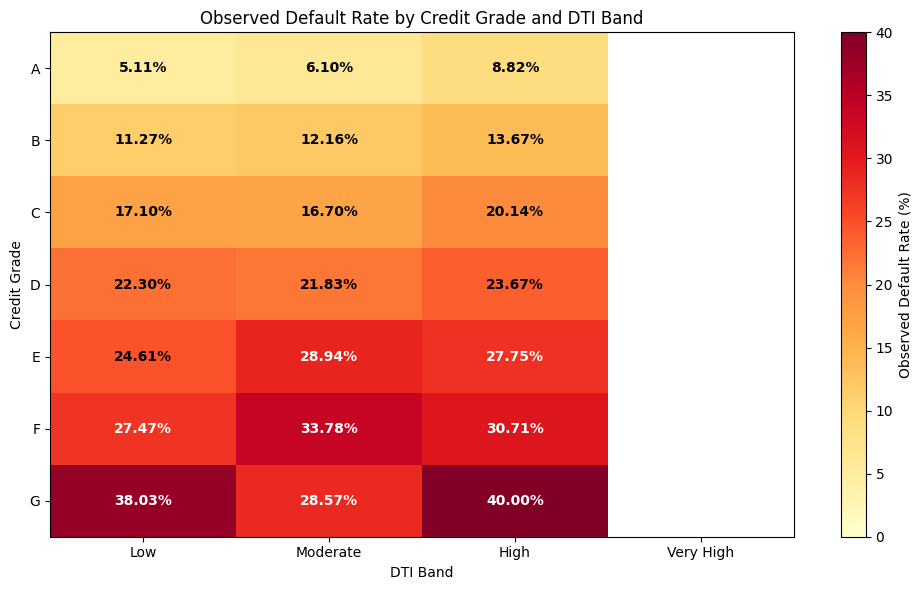

In [34]:

# Prepare data for the grade and DTI heatmap
grade_dti_pivot = grade_dti_analysis.pivot(
    index="grade",
    columns="dti_band",
    values="default_rate_pct"
)

dti_order = ["Low", "Moderate", "High", "Very High"]
grade_dti_pivot = grade_dti_pivot.reindex(columns=dti_order)

fig, ax = plt.subplots(figsize=(10, 6))

heatmap = ax.imshow(
    grade_dti_pivot,
    aspect="auto",
    cmap="YlOrRd",
    interpolation="nearest",
    vmin=0,
    vmax=40
)

# Add percentage values inside each box
for i in range(len(grade_dti_pivot.index)):
    for j in range(len(grade_dti_pivot.columns)):
        value = grade_dti_pivot.iloc[i, j]

        if pd.notna(value):
            text_color = "white" if value >= 25 else "black"
            ax.text(
                j, i, f"{value:.2f}%",
                ha="center",
                va="center",
                color=text_color,
                fontsize=10,
                fontweight="bold"
            )

# Configure labels and title
ax.set_xticks(range(len(grade_dti_pivot.columns)))
ax.set_xticklabels(grade_dti_pivot.columns)

ax.set_yticks(range(len(grade_dti_pivot.index)))
ax.set_yticklabels(grade_dti_pivot.index)

ax.set_title("Observed Default Rate by Credit Grade and DTI Band")
ax.set_xlabel("DTI Band")
ax.set_ylabel("Credit Grade")

fig.colorbar(
    heatmap,
    ax=ax,
    label="Observed Default Rate (%)"
)

plt.tight_layout()
plt.show()




**Key Insight:** Observed default rates generally increase from Grade A to the lower credit grades. Grade G with High DTI shows a 40.00% default rate, while Grade F with Moderate DTI shows 33.78%. Some grade–DTI combinations have relatively high observed default rates, highlighting the value of examining multiple risk factors together.

**Business Implication:** Combining credit grade and DTI can help identify borrower segments for closer review. However, the number of loans in each segment should be considered before drawing conclusions, particularly for Grades F and G, where sample sizes may be smaller.

**Note:** These results describe observed associations and do not establish causation.



### 6.8 Defaulted Loan Amount by Loan Purpose

This analysis calculates the original principal amount associated with defaulted loans across loan purposes. It complements default-rate analysis by identifying categories that contribute more to the portfolio's defaulted principal exposure.


In [35]:

# Calculate defaulted principal exposure by loan purpose
defaulted_purpose_analysis = (
    df[df["loan_status"] == 1]
    .groupby("purpose", dropna=False)
    .agg(
        defaulted_loans=("loan_status", "size"),
        defaulted_loan_amount=("loan_amnt", "sum")
    )
    .reset_index()
)

display(
    defaulted_purpose_analysis.sort_values(
        "defaulted_loan_amount", ascending=False
    )
)


,purpose,defaulted_loans,defaulted_loan_amount
2,debt_consolidation,1937,26355675
1,credit_card,391,5017975
11,small_business,330,4937200
9,other,447,3693700
4,home_improvement,270,3246825
6,major_purchase,162,1461925
0,car,106,780100
7,medical,83,778000
13,wedding,67,765250
5,house,44,555925


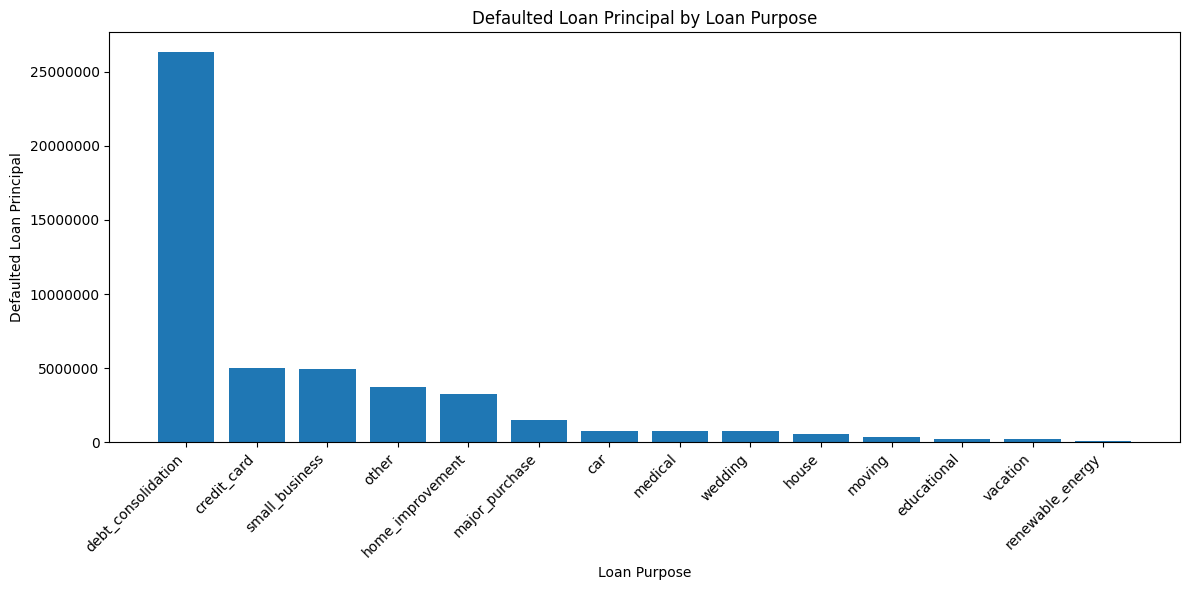

In [36]:

# Visualize defaulted principal exposure by loan purpose
purpose_exposure_chart = defaulted_purpose_analysis.sort_values(
    "defaulted_loan_amount", ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    purpose_exposure_chart["purpose"].fillna("Unknown").astype(str),
    purpose_exposure_chart["defaulted_loan_amount"]
)

plt.title("Defaulted Loan Principal by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Defaulted Loan Principal")
plt.xticks(rotation=45, ha="right")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()



**Key Insight:** Debt consolidation accounts for the largest defaulted principal exposure in the portfolio. Credit card and small business loans are the next major contributors.

**Business Implication:** Risk management should consider both the observed default rate and the total principal exposure associated with defaults. Loan purposes with larger exposure may warrant closer portfolio monitoring and further investigation.

**Note:** Defaulted principal represents the original loan amount associated with defaulted accounts; it is not the same as the lender's realized loss. Loan-purpose comparisons should also account for differences in the number of loans in each category.



## 6.10 Summary of Key Findings

This section consolidates the major patterns identified through exploratory data analysis and credit-risk segmentation. The findings will be compared with the SQL results and Power BI dashboard to maintain consistency across the project.


In [37]:

# Summarize the overall loan portfolio
total_loans = len(df)
defaulted_loans = (df["loan_status"] == 1).sum()
non_defaulted_loans = (df["loan_status"] == 0).sum()
default_rate = df["loan_status"].mean() * 100
total_loan_amount = df["loan_amnt"].sum()
defaulted_principal = df.loc[
    df["loan_status"] == 1, "loan_amnt"
].sum()

summary_metrics = pd.DataFrame({
    "Metric": [
        "Total Loans",
        "Non-Defaulted Loans",
        "Defaulted Loans",
        "Observed Default Rate (%)",
        "Total Loan Principal",
        "Defaulted Loan Principal"
    ],
    "Value": [
        total_loans,
        non_defaulted_loans,
        defaulted_loans,
        round(default_rate, 2),
        total_loan_amount,
        defaulted_principal
    ]
})

display(summary_metrics)


,Metric,Value
0,Total Loans,2.700300e+04
1,Non-Defaulted Loans,2.302600e+04
2,Defaulted Loans,3.977000e+03
3,Observed Default Rate (%),1.473000e+01
4,Total Loan Principal,2.994078e+08
5,Defaulted Loan Principal,4.848998e+07



## 7. Key Findings and Business Recommendations

### Key Findings

1. **Overall Portfolio Risk:** The dataset contains 27,003 loans, with 3,977 defaults and an observed default rate of 14.73%.

2. **Credit Grade:** Observed default rates generally increase toward lower credit grades, making credit grade an important dimension for risk segmentation.

3. **Debt-to-Income Ratio:** Higher DTI bands show higher observed default rates overall, although the pattern varies across credit grades.

4. **Interest Rate:** Loans in higher interest-rate bands exhibit higher observed default rates in this dataset. This is an association and does not establish causation.

5. **Loan Amount:** The Very High loan amount band has the highest observed default rate among the four loan amount bands.

6. **Loan Purpose:** Debt consolidation contributes the largest defaulted principal exposure among loan purposes.

7. **Combined Risk Segmentation:** Analyzing credit grade and DTI together reveals differences in observed default rates across borrower segments. Segment sizes should be considered when interpreting these rates.

### Business Recommendations

- Review underwriting criteria and repayment capacity across higher-risk credit grades.
- Include DTI and interest-rate bands in portfolio monitoring and risk segmentation.
- Monitor both default rates and defaulted principal exposure to understand different aspects of portfolio risk.
- Investigate loan-purpose categories with substantial defaulted principal exposure.
- Validate risk patterns using adequate sample sizes and additional borrower and repayment information before making lending-policy changes.

### Limitations

- The analysis describes historical associations and does not establish causal relationships.
- Defaulted loan principal represents the original principal of defaulted loans, not actual lender losses.
- Some credit-grade and DTI combinations may have small sample sizes, making their default rates less stable.
- The findings are based on the available dataset and may not generalize to other lending portfolios.
